<!-- CURRICULUM_HEADER_START -->
<div class="mh"><p class="mh-crumb"><a href="/series/forecasting/index.html">Forecasting with Machine Learning</a><span class="sep">·</span>Part 13 · Deep learning</p><p class="mh-facts"><span class="lvl lvl-advanced">Advanced</span></p><p class="mh-assumes">Python and pandas. Basic statistics. No prior forecasting.</p></div>
<!-- CURRICULUM_HEADER_END -->

::: {.callout-note appearance="simple" icon=false}
## TL;DR

N-BEATS and the Temporal Fusion Transformer (TFT) are two widely cited deep-learning forecasters. N-BEATS chains small blocks of fully connected layers: each forecasts a piece of the future and passes on the part of the past it could not explain, so the forecast is a sum of pieces, which one version labels trend and seasonality. TFT also reads inputs known in advance, such as the calendar, learns a weight for each input, attends across weeks and returns quantiles. On synthetic weekly harvests from five fields, backtested from 485 forecast origins, neither network beat LightGBM given the same inputs, and TFT cost an order of magnitude or more to fit. Adding known future inputs helped; swapping LightGBM for a network did not.

Backtest either network against your boosted model before switching.
:::

**What this found, in three lines**

- Harvest history only: LightGBM $7.2$ t/week mean absolute error; best N-BEATS $7.7$.
- With known future inputs: LightGBM $6.2$; TFT $6.7$, better only at 7 and 8 weeks ahead.
- The inputs were worth more than the architecture: they cut LightGBM's error by $1.07$ t/week.

In [1]:
import logging, sys, time, warnings
from pathlib import Path

warnings.filterwarnings("ignore")  # library chatter, including tqdm's notice on import
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from darts import TimeSeries
from darts.explainability import TFTExplainer
from darts.models import LightGBMModel, LinearRegressionModel, NBEATSModel, TFTModel
from darts.utils.likelihood_models import QuantileRegression

here = [Path.cwd(), *Path.cwd().parents]  # fallcolor is the site's colour module in tools/
sys.path.insert(0, str(next(p / "tools" for p in here if (p / "tools/fallcolor.py").exists())))
import fallcolor

fallcolor.palette.use("default")
for name in [n for n in logging.root.manager.loggerDict if "lightning" in n]:
    logging.getLogger(name).setLevel(logging.ERROR)  # hide the trainer's banners
torch.set_num_threads(2)
C1, C2, C3, C4 = fallcolor.palette.discrete("default")
P, H, L, SCALE = 52, 8, 52, 100.0      # season, horizon, lookback (weeks); t/week per model unit
FIELDS, SEASONS, TRAIN = 5, 8, 6 * 52  # fit on seasons 1-6, forecast seasons 7-8

## Two architectures in plain words

Both forecast all 8 weeks in one pass, as in [Multi-output models](../multi-output/multi_output_models.ipynb), and fit many series at once.

**N-BEATS reads only the target's own past.** Oreshkin and colleagues built it for univariate forecasts, with a lookback 2 to 7 times the horizon[^1]; here, 52 weeks. It chains **blocks** of fully connected layers. Each outputs a **forecast** of the next 8 weeks and a **backcast**, its reconstruction of its own input; the next block gets the input minus the backcast, so it works on what earlier blocks missed, and the forecasts are summed. **Generic** blocks learn their own output shapes; **interpretable** ones are split into a trend stack (a low-degree polynomial) and a seasonality stack (a short Fourier series)[^1].

```{mermaid}
flowchart TD
  X["last 52 weeks of harvest"] --> B1["block 1"]
  B1 -->|"input minus backcast"| B2["block 2"]
  B2 -->|"input minus backcast"| B3["block 3"]
  B1 -->|"forecast piece"| S["sum"]
  B2 -->|"forecast piece"| S
  B3 -->|"forecast piece"| S
  S --> F["next 8 weeks"]
  classDef indigo fill:#1d4a62,stroke:#c97d62,stroke-width:1.5px,color:#ffffff
  classDef ochre fill:#d69a2e,stroke:#3b1a18,stroke-width:1.5px,color:#3b1a18
  classDef sage fill:#95a87f,stroke:#3b1a18,stroke-width:1.5px,color:#3b1a18
  class X,F sage
  class B1,B2,B3 indigo
  class S ochre
```

**Figure 1 | N-BEATS.** Each block forecasts a piece and passes on what it missed.

**TFT is built for a mix of inputs.** Lim and colleagues separate static facts about a series, inputs **known in advance** (the calendar, a planned promotion) and inputs observed only in the past[^2]. A **variable selection network** gives each input a weight at each time step, the weights summing to 1. Four other parts complete it; you don't need them to read the results[^2]:

- An **LSTM** is a recurrent layer that reads the weeks in order and carries a running summary forward.
- **Attention** lets each forecast week draw, with learned weights, on whichever earlier weeks matter most.
- **Gates** are learned switches that can turn a layer nearly off, giving small datasets a simpler network.
- The **quantile loss** penalises under- and over-forecasts unequally, so each output lands on a chosen percentile, here the 10th, 50th and 90th ([Pinball loss and quantiles](../pinball-loss-and-quantiles.qmd)).

```{mermaid}
flowchart TD
  P["past 52 weeks: harvest and covariates"] --> VP["variable selection"]
  K["next 8 weeks: known covariates"] --> VK["variable selection"]
  VP --> E["LSTM encoder"]
  VK --> D["LSTM decoder"]
  E --> A["attention across all 60 weeks"]
  D --> A
  A --> Q["10th, 50th, 90th percentile per week"]
  classDef indigo fill:#1d4a62,stroke:#c97d62,stroke-width:1.5px,color:#ffffff
  classDef ochre fill:#d69a2e,stroke:#3b1a18,stroke-width:1.5px,color:#3b1a18
  classDef sage fill:#95a87f,stroke:#3b1a18,stroke-width:1.5px,color:#3b1a18
  class P,K sage
  class VP,VK,E,D,A indigo
  class Q ochre
```

**Figure 2 | TFT.** Past and known-future inputs are weighted, then combined.

## A fair backtest

A fair comparison changes only the model. The data are **synthetic**, from the generator in [Backtesting properly](../backtesting/backtesting_properly.ipynb): weekly harvest (t/week), one bell-shaped season a year of varying height and timing, plus autocorrelated noise, for five fields of eight seasons each. Three covariates are known in advance:

- **Week of the season**, as a sine and cosine ([Calendar and cyclical encodings](../calendar-encodings/calendar_and_cyclical_encodings.ipynb)).
- **A pre-season crop estimate**: the season's peak height plus noise, published at least 8 weeks before the season. It is informative by construction.
- **An irrelevant column** of noise, to see whether variable selection ignores it.

In [2]:
def simulate(seed, seasons=SEASONS):
    """Synthetic weekly harvest (t/week) as in Backtesting properly, plus a pre-season crop estimate."""
    rng = np.random.default_rng(seed)
    t = np.arange(seasons * P)
    size, peak = rng.normal(100, 20, seasons), rng.normal(26, 2.5, seasons)  # vary by season
    noise = np.zeros(len(t))
    for i in range(1, len(t)):  # AR(1) week-to-week noise
        noise[i] = 0.7 * noise[i - 1] + rng.normal(0, 4)
    y = np.clip(5 + size[t // P] * np.exp(-0.5 * ((t % P - peak[t // P]) / 5) ** 2) + noise, 0, None)
    estimate = size / 100 + np.random.default_rng(100 + seed).normal(0, 0.1, seasons)
    return y, estimate[t // P]


series, covariates = [], []
for field in range(FIELDS):
    y, estimate = simulate(seed=field)
    week = 2 * np.pi * (np.arange(len(y)) % P) / P
    series.append(TimeSeries.from_values(y / SCALE, columns=["harvest"]))
    covariates.append(TimeSeries.from_values(
        np.column_stack([np.sin(week), np.cos(week), estimate,
                         np.random.default_rng(200 + field).normal(0, 1, len(y))]),  # last column: pure noise
        columns=["week_sin", "week_cos", "crop_estimate", "irrelevant"]))
train = [s[:TRAIN] for s in series]

Darts' N-BEATS accepts past covariates only, so the comparison runs in two groups: harvest history only (with N-BEATS) and history plus known covariates (with TFT). Baselines are seasonal naive, ridge, and LightGBM with 52 lags and one model per horizon ([Direct vs recursive in Darts](../darts-direct-vs-recursive.qmd)). Networks are small, nothing is tuned, and each network runs with three seeds, since its result depends on its random starting weights.

In [3]:
NET = dict(n_epochs=40, batch_size=64, pl_trainer_kwargs=dict(  # quiet, CPU-only training
    enable_progress_bar=False, enable_model_summary=False, logger=False, enable_checkpointing=False,
    accelerator="cpu"))
LGBM = dict(n_estimators=200, learning_rate=0.05, num_leaves=15, verbose=-1, random_state=0,
            n_jobs=1)  # one thread: LightGBM's OpenMP and PyTorch's crash together on macOS
FUT = {"lags_future_covariates": list(range(H))}  # covariates at each of the 8 target weeks
MODELS = {  # name: (constructor taking a seed, uses known future covariates)
    "ridge": (lambda s: LinearRegressionModel(lags=L, output_chunk_length=H), False),
    "LightGBM": (lambda s: LightGBMModel(lags=L, output_chunk_length=H, **LGBM), False),
    "N-BEATS interpretable": (lambda s: NBEATSModel(L, H, generic_architecture=False, num_blocks=3,
        num_layers=2, layer_widths=64, random_state=s, **NET), False),
    "N-BEATS generic": (lambda s: NBEATSModel(L, H, num_stacks=6, num_blocks=1, num_layers=2,
        layer_widths=64, random_state=s, **NET), False),
    "ridge + covariates": (lambda s: LinearRegressionModel(lags=L, output_chunk_length=H, **FUT), True),
    "LightGBM + covariates": (lambda s: LightGBMModel(lags=L, output_chunk_length=H, **FUT, **LGBM), True),
    "TFT": (lambda s: TFTModel(L, H, hidden_size=16, num_attention_heads=4, dropout=0.1, random_state=s,
        likelihood=QuantileRegression([0.1, 0.5, 0.9]), **{**NET, "n_epochs": 30}), True),
}
SEEDS = {"N-BEATS interpretable": 3, "N-BEATS generic": 3, "TFT": 3}  # the rest are deterministic

Each model is fitted once on seasons 1 to 6 of all five fields, then forecasts 8 weeks ahead from every week of seasons 7 and 8, scored by mean absolute error (MAE, t/week) at each horizon $h$.

In [4]:
# Copy this. `series`: list of TimeSeries, one per field, one row per week, scaled near 1.
# `covariates`: matching list of known-in-advance inputs reaching at least H weeks past each origin.
def backtest(model, use_cov):
    cov = covariates if use_cov else None
    start = time.process_time()  # CPU seconds, steadier than wall-clock on a busy machine
    model.fit(train, future_covariates=cov)  # one global fit on seasons 1-6 of every field
    fit_s = time.process_time() - start
    q = isinstance(model, TFTModel)  # TFT can output quantiles; the others output one point
    forecasts = model.historical_forecasts(
        series, future_covariates=cov,
        start=TRAIN,                      # first forecast week: the start of season 7
        forecast_horizon=H,               # 8 weeks from each origin
        retrain=False,                    # reuse the fit above at every origin
        last_points_only=False,           # keep all 8 weeks of each forecast, not just the 8th
        predict_likelihood_parameters=q,  # TFT: return its q10, q50, q90 directly
        verbose=False)
    rows = []
    for f, fcs in enumerate(forecasts):  # one list of forecasts per field
        for fc in fcs:  # one 8-week forecast per origin
            w = np.asarray(fc.time_index)
            # TFT has columns q10, q50, q90, so [0, 1, -1] picks all three; a point model has one
            # column, so [0, 0, -1] copies it into lo, pred and hi (lo and hi are unused there).
            v = fc.values()[:, [0, int(q), -1]] * SCALE
            rows.append(pd.DataFrame(v, columns=["lo", "pred", "hi"]).assign(
                field=f, week=w, h=np.arange(1, H + 1), actual=series[f].values()[w, 0] * SCALE))
    return pd.concat(rows), fit_s


runs, times, fitted = [], [], {}
for name, (make, use_cov) in MODELS.items():
    for seed in range(SEEDS.get(name, 1)):
        df, fit_s = backtest(model := make(seed), use_cov)
        runs.append(df.assign(model=name, seed=seed))
        times.append({"model": name, "fit_s": fit_s})
        fitted.setdefault(name, []).append(model)
naive = runs[0].copy()  # seasonal naive: the same week last season
naive["pred"] = [series[f].values()[w - P, 0] * SCALE for f, w in zip(naive.field, naive.week)]
res = pd.concat(runs + [naive.assign(model="seasonal naive")], ignore_index=True)
res["abs_err"] = (res.pred - res.actual).abs()
print(f"{len(runs[0]) // H} forecast origins across the five fields")

485 forecast origins across the five fields


## The boosted model holds

On this data LightGBM matched or beat both networks on average, and the covariates mattered more than the choice between LightGBM and a network.

In [5]:
ORDER = ["seasonal naive", "ridge", "LightGBM", "N-BEATS interpretable", "N-BEATS generic",
         "ridge + covariates", "LightGBM + covariates", "TFT"]
by_h = res.groupby(["model", "seed", "h"]).abs_err.mean().unstack("h")  # MAE (t/week)
mae = by_h.groupby("model").mean().loc[ORDER]  # averaged over seeds
fit = pd.DataFrame(times).groupby("model").fit_s.mean()
seeds = by_h.mean(axis=1).groupby("model").agg(["min", "max"]).loc[list(SEEDS)].round(2)
print(f"mean MAE over h = 1-8, lowest and highest seed:\n{seeds}")
tft, lgb = mae.loc["TFT"], mae.loc["LightGBM + covariates"]
print(f"TFT ahead of LightGBM + covariates at h = {mae.columns[tft < lgb].tolist()}")
print(f"covariates cut LightGBM's mean MAE by {mae.loc['LightGBM'].mean() - lgb.mean():.2f}")
table = pd.DataFrame({"h=1": mae[1], "h=8": mae[8], "mean": mae.mean(axis=1), "fit (CPU s)": fit})
table.loc[ORDER].round(1).fillna("-")

mean MAE over h = 1-8, lowest and highest seed:
                        min   max
model                            
N-BEATS interpretable  7.92  8.32
N-BEATS generic        7.37  8.05
TFT                    6.55  6.88
TFT ahead of LightGBM + covariates at h = [7, 8]
covariates cut LightGBM's mean MAE by 1.07


,h=1,h=8,mean,fit (CPU s)
model,,,,
seasonal naive,14.8,14.8,14.8,-
ridge,3.9,12.9,8.9,0.0
LightGBM,3.4,10.5,7.2,1.1
N-BEATS interpretable,4.6,11.5,8.1,1.2
N-BEATS generic,3.9,11.2,7.7,1.7
ridge + covariates,3.8,11.4,8.2,0.0
LightGBM + covariates,3.4,8.5,6.2,1.4
TFT,5.2,8.2,6.7,16.8


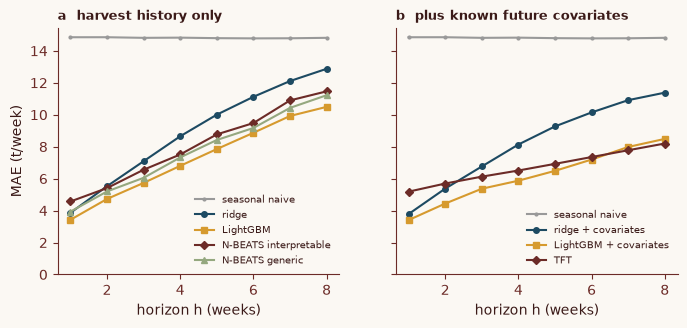

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.2), sharey=True)
for ax, names, title in [(axes[0], ORDER[:5], "a  harvest history only"),
                         (axes[1], ORDER[:1] + ORDER[5:], "b  plus known future covariates")]:
    for name, c, m in zip(names, ["0.6", C1, C2, C3, C4], ".osD^"):
        ax.plot(mae.columns, mae.loc[name], color=c, marker=m, ms=4, label=name)
    ax.set_title(title, loc="left", fontsize=9, fontweight="bold")
    ax.set(xlabel="horizon h (weeks)", ylim=(0, None))
    ax.legend(frameon=False, fontsize=7)
axes[0].set_ylabel("MAE (t/week)")
plt.show()

**Figure 3 | Backtest error by horizon.** MAE over 485 origins, networks averaged over three seeds. **a**, Harvest history only. **b**, Plus the three known covariates.

With history only, LightGBM had the lowest error at every horizon. Interpretable N-BEATS averaged $8.1$, ridge $8.9$ and seasonal naive $14.8$; the seed alone moved generic N-BEATS between $7.37$ and $8.05$, wider than its gap to LightGBM.

With covariates, TFT (seeds $6.55$ to $6.88$) was worst at $h = 1$, $5.2$ against LightGBM's $3.4$, and best only at $h = 7$ and $8$, $8.2$ against $8.5$ at $h = 8$. It cost an order of magnitude or more in CPU time here; the ratio to LightGBM varied from roughly 11 to 32 times across runs with machine load.

The next cell counts wins by season and checks TFT's 80% interval.

In [7]:
res["season"] = res.week // P + 1
per_season = res.groupby(["model", "field", "season"]).abs_err.mean().unstack("model")
for a, b in [("TFT", "LightGBM + covariates"), ("N-BEATS generic", "LightGBM")]:
    print(f"{a} beats {b} in {(per_season[a] < per_season[b]).sum()} of {len(per_season)} field-seasons")
t = res[res.model == "TFT"]
inside = (t.lo <= t.actual) & (t.actual <= t.hi)
print("TFT 10-90% interval coverage by seed:", inside.groupby(t.seed).mean().round(2).tolist())

TFT beats LightGBM + covariates in 3 of 10 field-seasons
N-BEATS generic beats LightGBM in 1 of 10 field-seasons
TFT 10-90% interval coverage by seed: [0.75, 0.84, 0.87]


Errors within a season move together (a late or small peak hurts every week of it), so the season, not the week, is the independent unit. TFT beat LightGBM with covariates in 3 of 10 field-seasons and generic N-BEATS beat LightGBM in 1. Ten field-seasons cannot separate models this close; [Backtest design](../backtest-design/backtest_design.ipynb) shows how many seasons a ranking needs. TFT's 80% intervals held the actual value $75\%$, $84\%$ and $87\%$ of the time across seeds; LightGBM would need [Quantile regression](../quantile-regression/quantile_regression.ipynb) or [Conformal prediction](../conformal-prediction/conformal_prediction.ipynb) for that.

## What the models show inside

Both architectures offer a view inside that needs care before it reaches a slide. Hooks on the interpretable N-BEATS record what each stack adds to one forecast.

trend stack 90 -> 59 t/week; seasonality stack peaks at 33


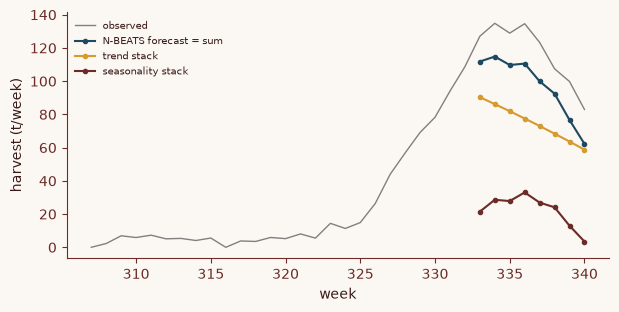

In [8]:
nb, parts = fitted["N-BEATS interpretable"][0], {}
for k, stack in zip(["trend stack", "seasonality stack"], nb.model.stacks_list):  # record stack outputs
    stack.register_forward_hook(
        lambda mod, inp, out, k=k: parts.update({k: out[1].detach().numpy().ravel() * SCALE}))
origin = TRAIN + 20  # week 20 of season 7, a few weeks before the peak
forecast = nb.predict(H, series=series[0][:origin + 1], verbose=False).values().ravel() * SCALE
assert np.allclose(parts["trend stack"] + parts["seasonality stack"], forecast)
print(f"trend stack {parts['trend stack'][0]:.0f} -> {parts['trend stack'][-1]:.0f} t/week; "
      f"seasonality stack peaks at {parts['seasonality stack'].max():.0f}")

weeks, ahead = np.arange(origin - 25, origin + 1 + H), np.arange(origin + 1, origin + 1 + H)
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(weeks, series[0].values()[weeks, 0] * SCALE, color="0.5", lw=1, label="observed")
for (label, v), c in zip({"N-BEATS forecast = sum": forecast, **parts}.items(), [C1, C2, C3]):
    ax.plot(ahead, v, color=c, marker="o", ms=3, label=label)
ax.set(xlabel="week", ylabel="harvest (t/week)")
ax.legend(frameon=False, fontsize=7, loc="upper left")
plt.show()

**Figure 4 | One N-BEATS forecast and its two stacks.**

The trend stack carries the level, falling from $90$ to $59$ t/week, and the seasonality stack adds up to $33$. "Seasonality" here is a Fourier series on the 8-week forecast window[^1], not the harvest season. The stacks are shapes, not causes.

For TFT, `TFTExplainer` reports each input's average selection weight (%) in the encoder (past 52 weeks) and decoder (8 forecast weeks).

In [9]:
imp = []
for m in fitted["TFT"]:  # selection weight per input (%), averaged over the fields' training seasons
    r = TFTExplainer(m, background_series=train, background_future_covariates=covariates).explain()
    imp.append([pd.concat(x).mean().rename(lambda c: c.replace("_futcov", "").replace("_target", ""))
                for x in (r.get_encoder_importance(), r.get_decoder_importance())])
for i, part in enumerate(["encoder (past 52 weeks)", "decoder (next 8 weeks)"]):
    table = pd.concat([x[i] for x in imp], axis=1, keys=["seed 0", "seed 1", "seed 2"])
    print(f"{part}, % of selection weight:\n{table.sort_values('seed 0', ascending=False).round(1)}\n")

encoder (past 52 weeks), % of selection weight:
               seed 0  seed 1  seed 2
harvest          67.4    27.7    42.6
crop_estimate    14.2    40.9    13.3
irrelevant        7.5     4.0     9.1
week_cos          6.0    17.1    31.7
week_sin          4.9    10.2     3.3

decoder (next 8 weeks), % of selection weight:
               seed 0  seed 1  seed 2
crop_estimate    64.8    13.0    53.8
week_sin         17.4    69.8    31.7
week_cos         13.9    12.3     6.2
irrelevant        3.9     4.9     8.3



Rankings flip by seed: the crop estimate took $64.8\%$ of the decoder weight in seed 0 but $13.0\%$ in seed 1, and the irrelevant column never fell below $3.9\%$. Check any importance you plan to cite with an ablation: drop the input and re-run the backtest.

## Key takeaways

- Score any deep model per horizon beside a boosted model with the same inputs; here TFT won only at the far end.
- Work on inputs before architecture: the covariates cut LightGBM's error by $1.07$ t/week, while swapping LightGBM for either network made it worse.
- Run each network with at least three seeds and report the range.
- Darts' N-BEATS cannot read known future inputs. If what matters arrives as a covariate, it is the wrong network.

::: {.callout-tip}
## What this means for you

All three points are my inference from this one synthetic setup.

**Inputs worth finding.** Realistic known-in-advance inputs for berries include planted area, bloom or fruit-set counts, the calendar, and a weather forecast used only up to its skilful lead time. The crop estimate here is informative by construction and flatters the covariate models.

**When a gap matters.** If a gap between two models is within the seed spread and does not hold across seasons, treat it as a tie and keep the cheaper model ([Backtest design](../backtest-design/backtest_design.ipynb)).

**Refit cost.** It grows with the number of series and how often you refit; time one refit on your own panel before committing. Wider evidence: [When deep learning helps](../when-deep-learning-helps.qmd) and [Time series foundation models](../time-series-foundation-models.qmd).
:::

## References

[^1]: Oreshkin, B. N., Carpov, D., Chapados, N. & Bengio, Y. N-BEATS: neural basis expansion analysis for interpretable time series forecasting. In *International Conference on Learning Representations* (2020). Preprint at https://arxiv.org/abs/1905.10437
[^2]: Lim, B., Arık, S. Ö., Loeff, N. & Pfister, T. Temporal Fusion Transformers for interpretable multi-horizon time series forecasting. *Int. J. Forecast.* **37**, 1748–1764 (2021). https://doi.org/10.1016/j.ijforecast.2021.03.012

<!-- CURRICULUM_FOOTER_START -->
<div class="mf"><a class="mf-prev" href="/blogs/when-deep-learning-helps.html"><span>Previous</span>When deep learning helps</a><a class="mf-up" href="/series/forecasting/index.html"><span>Series</span>Forecasting with Machine Learning</a><a class="mf-next" href="/blogs/time-series-foundation-models.html"><span>Next</span>Time series foundation models</a></div>
<!-- CURRICULUM_FOOTER_END -->